In [22]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

G = 9.81
ROOT = Path.cwd().parent
DATA = ROOT / "data"
print(ROOT)

d:\Wave Breaking Data Summer Internship


In [23]:
def parse_case_name(name):
    """'test_BK_0d224_1d073_bak_surf1_pert.mat' -> ('BK', [0.224, 1.073])."""
    parts = Path(name).stem.split("_")
    family = parts[1]
    params = [float(p.replace("d", ".")) for p in parts[2:] if p[0].isdigit() and "d" in p]
    return family, params

def load_case(path, Tp=None, fields=("eta", "ux", "uy")):
    """Return dict with fields as (t, x) float64 arrays plus grid and wave scales."""
    path = Path(path)
    if path.suffix == ".npz":
        d = np.load(path)
        arrs = {k: d[k].astype(np.float64) for k in fields}           # already (t, x)
        x, t = d["x"].ravel(), d["t"].ravel()
        case = str(d["case"])
    else:
        from pymatreader import read_mat
        d = read_mat(str(path), variable_names=["sfr3", "x1", "time_vec", "time_len_min", "case_name"])
        nt = int(d["time_len_min"])
        arrs = {k: np.asarray(d["sfr3"][k], dtype=np.float64)[:, :nt].T for k in fields}  # (x,t) -> (t,x)
        x, t = np.asarray(d["x1"]).ravel(), np.asarray(d["time_vec"]).ravel()[:nt]
        case = str(d.get("case_name", path.stem))
    if np.isnan(arrs["eta"]).all():
        raise ValueError(f"{path.name}: eta is entirely NaN (failed simulation)")
    N = x.size
    dx = (x[-1] - x[0]) / (N - 1)
    L = dx * N                                                         # periodic length
    family, params = parse_case_name(case if case.startswith("test_") else path.name)
    if Tp is None:
        if family in ("BK", "MXBK"):
            Tp = params[1]
        else:
            raise ValueError(f"Give Tp explicitly for family {family} (params {params})")
    omega = 2 * np.pi / Tp
    kp = omega**2 / G
    return dict(**arrs, x=x, t=t, N=N, dx=dx, L=L, dt=t[1] - t[0], case=case,
                family=family, params=params, Tp=Tp, omega=omega, kp=kp, cp=omega / kp)


In [24]:
def wavenumbers(N, dx):
    return 2 * np.pi * np.fft.rfftfreq(N, d=dx)

def ddx(f, k):
    return np.fft.irfft(1j * k * np.fft.rfft(f, axis=-1), f.shape[-1], axis=-1)

def lowpass(f, k, kc):
    F = np.fft.rfft(f, axis=-1); F[..., k > kc] = 0
    return np.fft.irfft(F, f.shape[-1], axis=-1)

def integrate_x(q, k):
    """Periodic antiderivative; returns (psi with zero mean, mean of q)."""
    Q = np.fft.rfft(q, axis=-1)
    qbar = Q[..., 0].real / q.shape[-1]
    Q[..., 0] = 0
    Q[..., 1:] /= 1j * k[1:]
    return np.fft.irfft(Q, q.shape[-1], axis=-1), qbar

def ddt4(f, dt):
    """4th-order central difference along axis 0 (time); NaN at the 2 edge rows each side."""
    out = np.full_like(f, np.nan)
    out[2:-2] = (-f[4:] + 8 * f[3:-1] - 8 * f[1:-3] + f[:-4]) / (12 * dt)
    return out


In [25]:
def hos_vertical_velocity(eta, psi, k, M=4, depth=np.inf):
    # HOS Dirichlet-to-Neumann: W = phi_z at z = eta
    N = eta.size
    th = np.ones_like(k) if np.isinf(depth) else np.tanh(k * depth)
    def dz(f, n):
        fac = k**n * (th if n % 2 else 1.0)
        return np.fft.irfft(np.fft.rfft(f) * fac, N)
    fact = np.cumprod([1.0] + list(range(1, M + 1)))
    phi = [psi]
    for m in range(2, M + 1):
        phi.append(-sum(eta**l / fact[l] * dz(phi[m - l - 1], l) for l in range(1, m)))
    return sum(eta**l / fact[l] * dz(phi[m - 1], l + 1)
               for m in range(1, M + 1) for l in range(M - m + 1))


In [26]:
def test_hos(N=2048, steep=0.2):
    # unit test of the HOS operator against an exact potential field
    L = 2 * np.pi; x = np.arange(N) * L / N; k = wavenumbers(N, L / N)
    ks, amps = np.array([8, 10, 12, 15]), np.array([1, .8, .6, .3]); ph = np.array([0.3, 1.9, 4.0, 5.2])
    a = amps / amps.sum() * steep / ks.mean(); A = a * np.sqrt(G / ks)
    eta = sum(ai * np.cos(kk * x + p) for ai, kk, p in zip(a, ks, ph))
    psi = sum(Ai * np.exp(kk * eta) * np.sin(kk * x + p) for Ai, kk, p in zip(A, ks, ph))
    Wex = sum(Ai * kk * np.exp(kk * eta) * np.sin(kk * x + p) for Ai, kk, p in zip(A, ks, ph))
    for M in (2, 4, 6):
        err = np.abs(hos_vertical_velocity(eta, psi, k, M) - Wex).max() / np.abs(Wex).max()
        print(f"  M={M}: rel. max error {err:.1e}")


In [27]:
from scipy.interpolate import CubicSpline

def _hilbert(f, kk):
    """Hilbert transform with symbol -i*sign(k) (rfft wavenumbers kk >= 0)."""
    return np.fft.irfft(-1j * np.fft.rfft(f) * (kk > 0), f.size)

def _dxi(f, kk):
    return np.fft.irfft(1j * kk * np.fft.rfft(f), f.size)

def _periodic_interp(xg, fg, L, xq):
    """Periodic cubic-spline interpolation of fg(xg) at points xq."""
    xe = np.append(xg, xg[0] + L); fe = np.append(fg, fg[0])
    cs = CubicSpline(xe, fe, bc_type="periodic")
    return cs(xg[0] + np.mod(xq - xg[0], L))

def conformal_vertical_velocity(eta, psi_per, x, L, tol=1e-10, maxit=500, relax=0.5,
                                return_info=False):
    """Exact deep-water potential-flow W = phi_z at z = eta(x) given psi_per(x) (periodic
    surface potential, zero mean). Single-valued periodic surface; no small-slope expansion.
    Conformal map z(w) = w + i*h0 + F(w), F analytic & decaying in the lower half-plane."""
    N = x.size
    kk = 2 * np.pi * np.fft.rfftfreq(N, d=L / N)
    xi = x.copy()                                       # uniform grid in the mapped variable
    y = eta.copy()
    for it in range(maxit):                             # solve y(xi) = eta(xi + H[y](xi))
        xs = xi + _hilbert(y, kk)
        y_new = _periodic_interp(x, eta, L, xs)
        err = np.abs(y_new - y).max()
        y = (1 - relax) * y + relax * y_new
        if err < tol:
            break
    xs = xi + _hilbert(y, kk)
    Phi = _periodic_interp(x, psi_per, L, xs)           # surface potential at mapped points
    Psi = -_hilbert(Phi, kk)                            # harmonic conjugate on the boundary
    zxi = 1 + _dxi(xs - xi, kk) + 1j * _dxi(y, kk)      # dz/dxi
    fxi = _dxi(Phi, kk) + 1j * _dxi(Psi, kk)            # df/dxi
    cvel = fxi / zxi                                    # u - i w
    w_xi = -cvel.imag
    if np.any(np.diff(np.append(xs, xs[0] + L)) <= 0):
        raise ValueError("conformal map is not monotone in x (surface too steep / under-resolved)")
    W = _periodic_interp(xs, w_xi, L, x)               # back to the physical uniform grid
    return (W, dict(iterations=it + 1, residual=err)) if return_info else W


def test_conformal(N=4096):
    L = 2 * np.pi; x = np.arange(N) * L / N
    ks, amps, ph = np.array([8, 10, 12, 15]), np.array([1, .8, .6, .3]), np.array([0.3, 1.9, 4.0, 5.2])
    for steep in (0.4, 0.8, 1.2):
        a = amps / amps.sum() * steep / ks.mean(); A = a * np.sqrt(G / ks)
        eta = sum(ai * np.cos(kk * x + p) for ai, kk, p in zip(a, ks, ph))
        psi = sum(Ai * np.exp(kk * eta) * np.sin(kk * x + p) for Ai, kk, p in zip(A, ks, ph))
        Wex = sum(Ai * kk * np.exp(kk * eta) * np.sin(kk * x + p) for Ai, kk, p in zip(A, ks, ph))
        W = conformal_vertical_velocity(eta, psi - psi.mean(), x, L)
        print(f"  max slope {np.abs(np.gradient(eta, x)).max():.2f}: rel. max error {np.abs(W - Wex).max() / np.abs(Wex).max():.1e}")

print("conformal unit test:"); test_conformal()


conformal unit test:
  max slope 0.34: rel. max error 3.9e-08
  max slope 0.67: rel. max error 6.2e-08
  max slope 1.01: rel. max error 7.5e-07


In [28]:
print("HOS unit test:"); test_hos()
case = load_case(DATA / "for_claude" / "BK_0d224_1d073_core.npz")
# case = load_case(DATA / "test_BK_0d224_1d073_bak_surf1_pert.mat")   # same data, slower, ~1.3 GB RAM
eta, ux, uy, t = case["eta"], case["ux"], case["uy"], case["t"]
k = wavenumbers(case["N"], case["dx"])
kp, cp = case["kp"], case["cp"]
print(f"{case['case']}: L={case['L']:.2f} m, dx={case['dx']*1e3:.2f} mm, Tp={case['Tp']} s, "
      f"kp={kp:.2f} rad/m, cp={cp:.3f} m/s, L/lambda_p={case['L']*kp/2/np.pi:.1f}")


HOS unit test:
  M=2: rel. max error 2.2e-02
  M=4: rel. max error 5.6e-04
  M=6: rel. max error 1.5e-05
test_BK_0d224_1d073_pert5: L=133.34 m, dx=8.14 mm, Tp=1.073 s, kp=3.50 rad/m, cp=1.675 m/s, L/lambda_p=74.2


In [29]:
eta_x = ddx(eta, k)
eta_t = ddt4(eta, case["dt"])
def kinematic_fit(i0, i1):
    A = np.column_stack([uy[i0:i1].ravel(), (ux * eta_x)[i0:i1].ravel()])
    y = eta_t[i0:i1].ravel()
    (a, b), *_ = np.linalg.lstsq(A, y, rcond=None)
    r = y - (uy - ux * eta_x)[i0:i1].ravel()
    return a, b, np.sqrt(np.mean(r**2) / np.mean(y**2))
for lab, (t0, t1) in {"calm": (0.5, 4.5), "breaking": (6.9, 8.0)}.items():
    i0, i1 = np.searchsorted(t, [t0, t1])
    a, b, rel = kinematic_fit(i0, i1)
    print(f"kinematic fit {lab} {t0}-{t1}s: a={a:.3f}, b={b:.3f}, rel. residual={rel:.3f}")


kinematic fit calm 0.5-4.5s: a=0.997, b=-0.872, rel. residual=0.036
kinematic fit breaking 6.9-8.0s: a=1.022, b=-0.232, rel. residual=1.164


In [30]:
KC = 20 * kp            # target resolution (simulator scale)
T_SKIP = 1.5            # discard start-up transient
nt, N = eta.shape
dW = np.full((nt, N), np.nan, np.float32)        # conformal (the target)
dW_hos = np.full((nt, N), np.nan, np.float32)    # HOS M=6 (diagnostic only)
slope_f = np.zeros((nt, N), np.float32)
for i in range(nt):
    e, w, u = (lowpass(f[i], k, KC) for f in (eta, uy, ux))
    ex = ddx(e, k)
    slope_f[i] = np.abs(ex)
    psi, _ = integrate_x(u + w * ex, k)
    dW_hos[i] = w - lowpass(hos_vertical_velocity(e, psi, k, 6), k, KC)
    try:
        dW[i] = w - conformal_vertical_velocity(e, psi, case["x"], case["L"])
    except ValueError:                           # map not monotone: overturning at this scale
        pass
dW_nd = dW / cp
B = ux / cp
valid = np.isfinite(dW) & (slope_f < 1.3) & (t[:, None] >= T_SKIP)
print(f"valid fraction: {valid.mean():.3f}; failed snapshots: {np.isnan(dW).all(1).sum()}")
# delta W for every snapshot: conformal (exact) DtN; HOS M=6 kept for comparison

valid fraction: 0.850; failed snapshots: 0


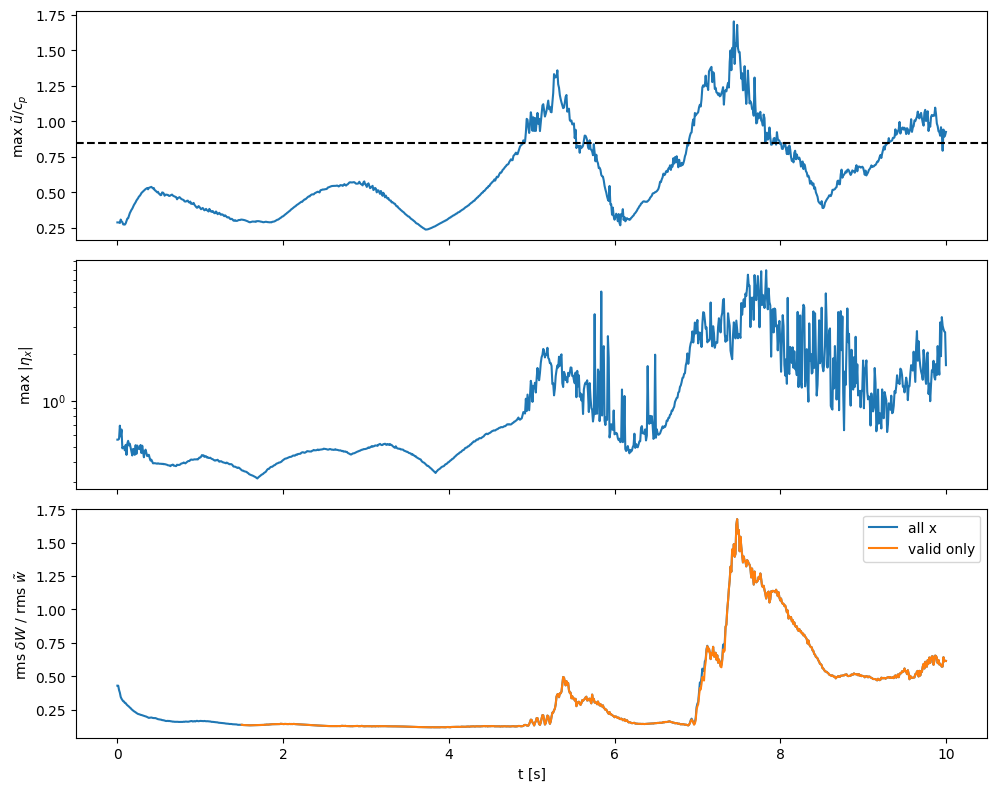

In [32]:
rms_w = np.sqrt((uy**2).mean(1))
fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
ax[0].plot(t, B.max(1)); ax[0].axhline(0.85, ls="--", c="k"); ax[0].set_ylabel(r"max $\tilde u/c_p$")
ax[1].plot(t, np.abs(eta_x).max(1)); ax[1].set_ylabel(r"max $|\eta_x|$"); ax[1].set_yscale("log")
ax[2].plot(t, np.sqrt((dW**2).mean(1)) / rms_w, label="all x")
ax[2].plot(t, [np.sqrt((dW[i][valid[i]]**2).mean()) / rms_w[i] if valid[i].any() else np.nan
               for i in range(nt)], label="valid only")
ax[2].set_ylabel(r"rms $\delta W$ / rms $\tilde w$"); ax[2].set_xlabel("t [s]"); ax[2].legend()
fig.tight_layout(); plt.show()
# time summary

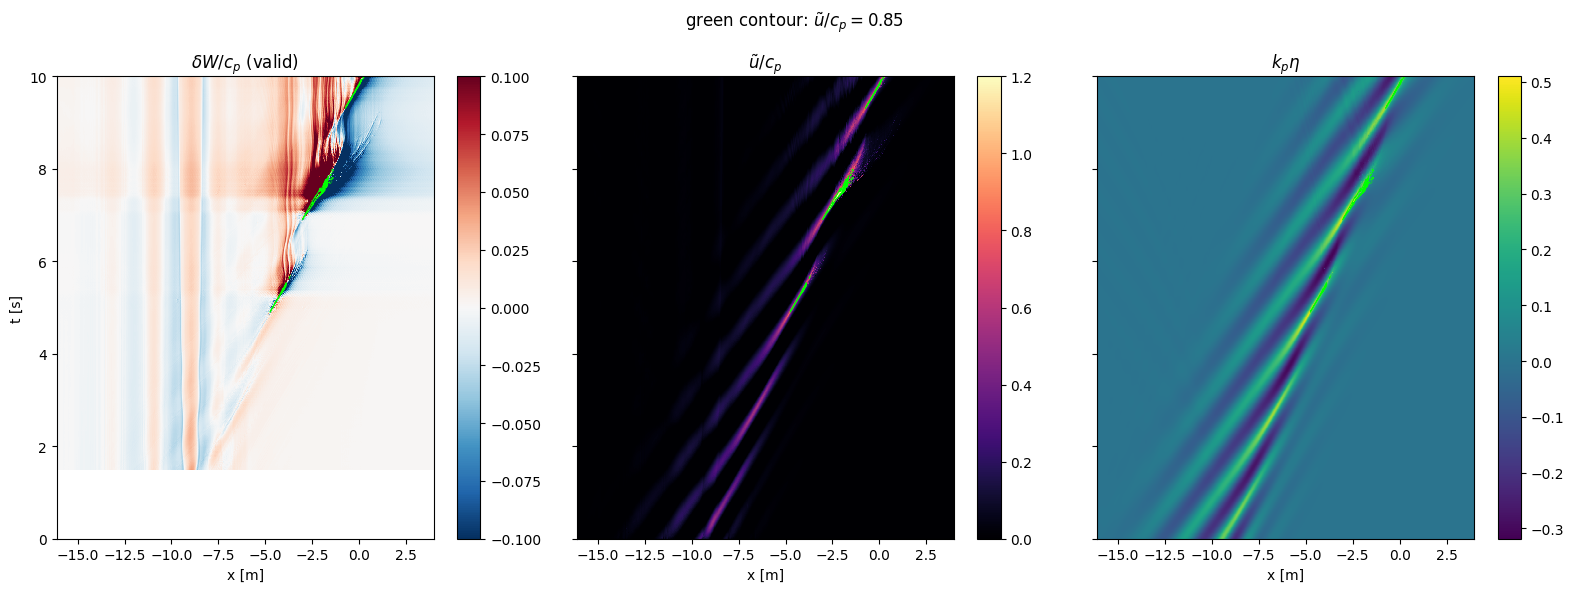

In [33]:
env = np.abs(eta).max(0)                                    # max over time at each x
xin = case["x"][env > 0.05 * env.max()]
xlo, xhi = xin.min() - 2, xin.max() + 2                      # group footprint + 2 m padding
sel = (case["x"] >= xlo) & (case["x"] <= xhi)
xs = case["x"][sel]
ext = [xlo, xhi, t[0], t[-1]]
fig, ax = plt.subplots(1, 3, figsize=(16, 6), sharey=True)
panels = [(np.where(valid, dW_nd, np.nan)[:, sel], r"$\delta W/c_p$ (valid)", "RdBu_r", (-0.1, 0.1)),
          (B[:, sel], r"$\tilde u/c_p$", "magma", (0, 1.2)),
          (eta[:, sel] * kp, r"$k_p\eta$", "viridis", (None, None))]
for a_, (Z, title, cmap, (lo, hi)) in zip(ax, panels):
    im = a_.imshow(Z, aspect="auto", origin="lower", extent=ext, cmap=cmap, vmin=lo, vmax=hi,
                   interpolation="nearest")
    a_.contour(xs, t, B[:, sel], levels=[0.85], colors="lime", linewidths=0.7)
    a_.set_title(title); a_.set_xlabel("x [m]"); fig.colorbar(im, ax=a_)
ax[0].set_ylabel("t [s]")
fig.suptitle("green contour: $\\tilde u/c_p = 0.85$")
fig.tight_layout(); plt.show()


In [34]:
def transfer(i, band=(0.6, 1.5)):
    e, w, u = (lowpass(f[i], k, KC) for f in (eta, uy, ux))
    psi, _ = integrate_x(u + w * ddx(e, k), k)
    Fw, Fp = np.fft.rfft(w), np.fft.rfft(w - np.nan_to_num(dW[i]))
    m = (k > band[0] * kp) & (k < band[1] * kp)
    H = (Fw[m] * np.conj(Fp[m])).sum() / (np.abs(Fp[m])**2).sum()
    return abs(H), np.degrees(np.angle(H))
for tt in (0.5, 1, 2, 3, 4, 6, 9):
    amp, ph = transfer(np.searchsorted(t, tt))
    print(f"t={tt:4.1f}s  |w/W_pf|={amp:.3f}  phase={ph:+.1f} deg")

t= 0.5s  |w/W_pf|=0.887  phase=+2.1 deg
t= 1.0s  |w/W_pf|=1.133  phase=-3.5 deg
t= 2.0s  |w/W_pf|=1.049  phase=-4.2 deg
t= 3.0s  |w/W_pf|=1.010  phase=-1.7 deg
t= 4.0s  |w/W_pf|=0.991  phase=-0.6 deg
t= 6.0s  |w/W_pf|=1.031  phase=-5.1 deg
t= 9.0s  |w/W_pf|=0.777  phase=+4.9 deg


stationary part explains 0.89 of calm δW variance in the group region


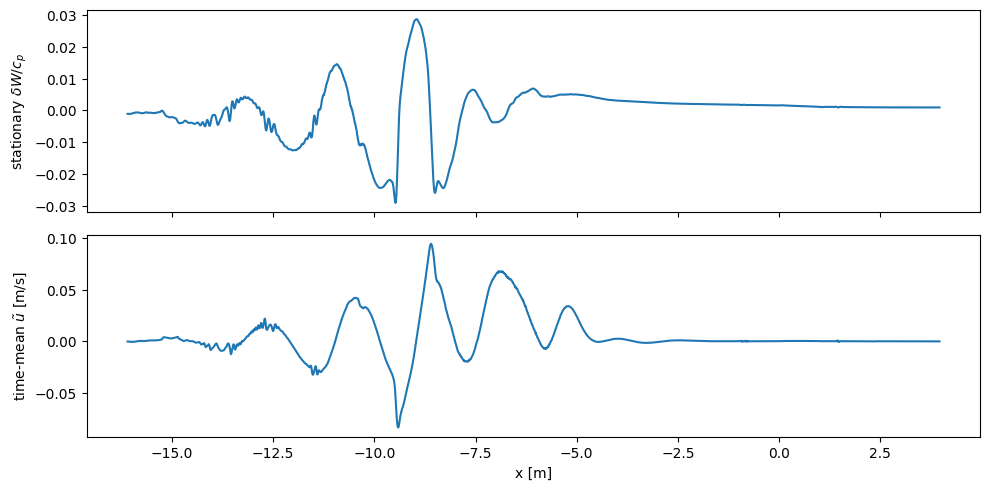

In [35]:
T0, T1 = 1.5, 4.0
win = (t >= T0) & (t <= T1)
dW_stat = np.nanmean(dW[win], axis=0)
grp = (case["x"] > xlo) & (case["x"] < xhi)
D = np.nan_to_num(dW[win][:, grp])
frac = 1 - ((D - dW_stat[grp])**2).sum() / (D**2).sum()
print(f"stationary part explains {frac:.2f} of calm δW variance in the group region")
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(case["x"][grp], dW_stat[grp] / cp); ax[0].set_ylabel(r"stationary $\delta W/c_p$")
ax[1].plot(case["x"][grp], ux[win][:, grp].mean(0)); ax[1].set_ylabel(r"time-mean $\tilde u$ [m/s]")
ax[1].set_xlabel("x [m]"); fig.tight_layout(); plt.show()
# time-mean of δW at each x over a calm window

In [36]:
def dW_at(i, M, kc):    # crest δW sensitivity to HOS order M and filter cutoff
    e, w, u = (lowpass(f[i], k, kc) for f in (eta, uy, ux))
    psi, _ = integrate_x(u + w * ddx(e, k), k)
    return w - lowpass(hos_vertical_velocity(e, psi, k, M), k, kc)

for tt in (3.0, 4.8, 5.0, 5.2, 5.5, 6.0):
    i = np.searchsorted(t, tt); c = np.argmax(ux[i])
    row = " | ".join(f"kc{f}: " + "/".join(f"{dW_at(i, M, f*kp)[c]/cp:+.3f}" for M in (4, 6, 8))
                     for f in (10, 20, 40))
    print(f"t={tt:3.1f} u/cp={ux[i, c]/cp:4.2f} | {row}")

t=3.0 u/cp=0.56 | kc10: -0.001/-0.003/-0.002 | kc20: -0.008/-0.007/-0.008 | kc40: -0.007/-0.007/-0.007
t=4.8 u/cp=0.77 | kc10: -0.006/-0.002/-0.004 | kc20: -0.016/+0.001/-0.007 | kc40: -0.004/+0.001/+0.002
t=5.0 u/cp=1.02 | kc10: +0.010/+0.003/+0.006 | kc20: +0.016/+0.027/+0.022 | kc40: -0.022/+0.043/+0.001
t=5.2 u/cp=1.14 | kc10: -0.037/-0.049/-0.044 | kc20: -0.056/-0.071/-0.059 | kc40: -0.104/-0.066/+0.058
t=5.5 u/cp=0.98 | kc10: -0.005/-0.013/-0.010 | kc20: -0.010/-0.003/-0.006 | kc40: -0.104/-0.096/-0.099
t=6.0 u/cp=0.31 | kc10: -0.037/-0.037/-0.037 | kc20: -0.041/-0.041/-0.041 | kc40: -0.044/-0.043/-0.043


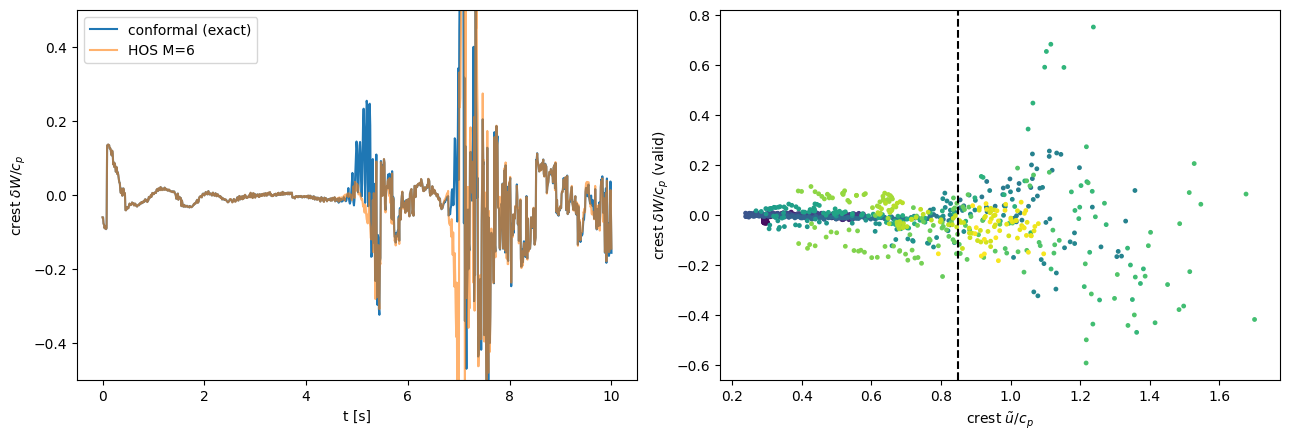

In [37]:
ci = np.argmax(ux, axis=1)
rows = np.arange(nt)
crest_cm, crest_hos = dW[rows, ci] / cp, dW_hos[rows, ci] / cp
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(t, crest_cm, label="conformal (exact)"); ax[0].plot(t, crest_hos, alpha=0.6, label="HOS M=6")
ax[0].set_ylim(-0.5, 0.5); ax[0].set_xlabel("t [s]"); ax[0].set_ylabel(r"crest $\delta W/c_p$"); ax[0].legend()
ok = valid[rows, ci]
ax[1].scatter(B[rows, ci][ok], crest_cm[ok], s=6, c=t[ok], cmap="viridis")
ax[1].axvline(0.85, ls="--", c="k"); ax[1].set_xlabel(r"crest $\tilde u/c_p$"); ax[1].set_ylabel(r"crest $\delta W/c_p$ (valid)")
fig.tight_layout(); plt.show()

### Batch Survey

In [38]:
import time, gc

KC_FACTOR, T_SKIP, B_ON = 20, 1.5, 0.85
OUT_DIR = DATA / "for_claude" / "summaries"
OUT_DIR.mkdir(parents=True, exist_ok=True)
TP_OVERRIDE = {}          # e.g. {"test_MXBKBW_0d183_1d918_0d826_bak_surf1_pert.mat": 1.918}

def spectral_periods(eta0, k):
    """Periods from the initial spectrum via deep-water dispersion: mean-k (Tm) and peak (Tpk)."""
    S = np.abs(np.fft.rfft(eta0))**2
    km, kpk = (k * S).sum() / S.sum(), k[np.argmax(S)]
    to_T = lambda kk: 2 * np.pi / np.sqrt(G * kk)
    return to_T(km), to_T(kpk), S

def summarise_case(path, Tp=None):
    family, params = parse_case_name(Path(path).name)
    tp_source = "override" if Tp is not None else "name"
    if Tp is None and family not in ("BK", "MXBK"):
        Tp = params[1]                                   # tentative: 2nd number (your renaming convention)
        tp_source = "name (tentative, 2nd number)"
    c = load_case(path, Tp=Tp)
    eta, ux, uy, t = c["eta"], c["ux"], c["uy"], c["t"]
    k = wavenumbers(c["N"], c["dx"]); kp, cp = c["kp"], c["cp"]; KC = KC_FACTOR * kp
    Tm, Tpk, S0 = spectral_periods(eta[0], k)
    # kinematic fit in a calm window (first 40% of the record after the start-up)
    eta_x = ddx(eta, k); eta_t = ddt4(eta, c["dt"])
    i0, i1 = np.searchsorted(t, [0.5, min(4.5, 0.45 * t[-1])])
    A = np.column_stack([uy[i0:i1].ravel(), (ux * eta_x)[i0:i1].ravel()])
    (a, b), *_ = np.linalg.lstsq(A, eta_t[i0:i1].ravel(), rcond=None)
    del eta_t, A
    # crest-following series (crest = location of max u) + conformal δW at every snapshot
    nt = len(t); ci = np.argmax(ux, axis=1)
    crest = dict(t=t, x=c["x"][ci], B=ux[np.arange(nt), ci] / cp, eta=eta[np.arange(nt), ci] * kp,
                 dW=np.full(nt, np.nan), slope=np.zeros(nt), ok=np.zeros(nt, bool))
    dW_mean_calm = np.zeros(c["N"]); n_calm = 0; dW_sq_calm = 0.0
    calm = (t >= T_SKIP) & (t <= min(4.0, 0.4 * t[-1]))
    for i in range(nt):
        e, w, u = (lowpass(f[i], k, KC) for f in (eta, uy, ux))
        ex = ddx(e, k)
        psi, _ = integrate_x(u + w * ex, k)
        try:
            d = w - conformal_vertical_velocity(e, psi, c["x"], c["L"])
        except ValueError:
            continue
        crest["dW"][i] = d[ci[i]] / cp
        crest["slope"][i] = abs(ex[ci[i]])
        crest["ok"][i] = (crest["slope"][i] < 1.3) and (t[i] >= T_SKIP)
        if calm[i]:
            dW_mean_calm += d; dW_sq_calm += (d**2).sum(); n_calm += 1
    dW_mean_calm /= max(n_calm, 1)
    stat_frac = (dW_mean_calm**2).sum() * n_calm / dW_sq_calm if n_calm else np.nan
    Bmax = ux.max(1) / cp
    up = t[np.where((Bmax[1:] >= B_ON) & (Bmax[:-1] < B_ON))[0] + 1]
    onsets = up[np.r_[True, np.diff(up) > 0.5]] if up.size else up      # merge re-crossings < 0.5 s apart
    return dict(case=c["case"], family=c["family"], params=np.array(c["params"]), Tp=c["Tp"],
                tp_source=tp_source, Tm_spec=Tm, Tpk_spec=Tpk, S0=S0.astype(np.float32), k=k.astype(np.float32),
                kp=kp, cp=cp, L=c["L"], dx=c["dx"], nt=nt, t_end=t[-1],
                kin_a=a, kin_b=b, Bmax=Bmax, slope_max=np.abs(eta_x).max(1), onsets=onsets,
                stat_frac=stat_frac, dW_stat=dW_mean_calm.astype(np.float32),
                **{f"crest_{key}": v for key, v in crest.items()})

files = sorted(p for p in DATA.glob("*.mat"))
print(f"{len(files)} cases found")
for p in files:
    out = OUT_DIR / f"summary_{p.stem.replace('_bak_surf1_pert', '')}.npz"
    if out.exists():
        print(f"skip (done): {p.name}"); continue
    t0 = time.time()
    try:
        s = summarise_case(p, Tp=TP_OVERRIDE.get(p.name))
        np.savez(out, **s)
        print(f"{p.name}: Tp={s['Tp']} ({s['tp_source']}), spectral Tm={s['Tm_spec']:.3f} s, "
              f"name numbers={s['params']}\n    onsets={np.round(s['onsets'], 2)}  max B={s['Bmax'].max():.2f}  "
              f"kin b={s['kin_b']:.3f}  stationary={s['stat_frac']:.2f}  [{time.time() - t0:.0f}s]")
    except Exception as err:
        print(f"{p.name}: FAILED - {type(err).__name__}: {err}")
    gc.collect()

20 cases found
test_BK_0d224_1d073_bak_surf1_pert.mat: Tp=1.073 (name), spectral Tm=1.055 s, name numbers=[0.224 1.073]
    onsets=[4.9  5.63 6.9  7.92 9.31 9.97]  max B=1.70  kin b=-0.872  stationary=0.89  [171s]
test_BK_0d236_1d132_bak_surf1_pert.mat: Tp=1.132 (name), spectral Tm=1.114 s, name numbers=[0.236 1.132]
    onsets=[2.98 5.06 7.5  8.49]  max B=1.56  kin b=-0.528  stationary=0.20  [161s]
test_BK_0d237_1d091_bak_surf1_pert.mat: Tp=1.091 (name), spectral Tm=1.073 s, name numbers=[0.237 1.091]
    onsets=[2.87 4.85 6.22 7.22 8.21 9.68]  max B=1.67  kin b=-0.421  stationary=0.18  [153s]
test_BK_0d239_1d435_bak_surf1_pert.mat: Tp=1.435 (name), spectral Tm=1.413 s, name numbers=[0.239 1.435]
    onsets=[3.72 5.11 6.55 9.68]  max B=1.78  kin b=-0.411  stationary=0.83  [166s]
test_BK_0d23_1d42_bak_surf1_pert.mat: Tp=1.42 (name), spectral Tm=1.397 s, name numbers=[0.23 1.42]
    onsets=[6.29 7.94]  max B=2.05  kin b=-0.863  stationary=0.90  [156s]
test_BK_0d243_1d223_bak_surf1_pert.

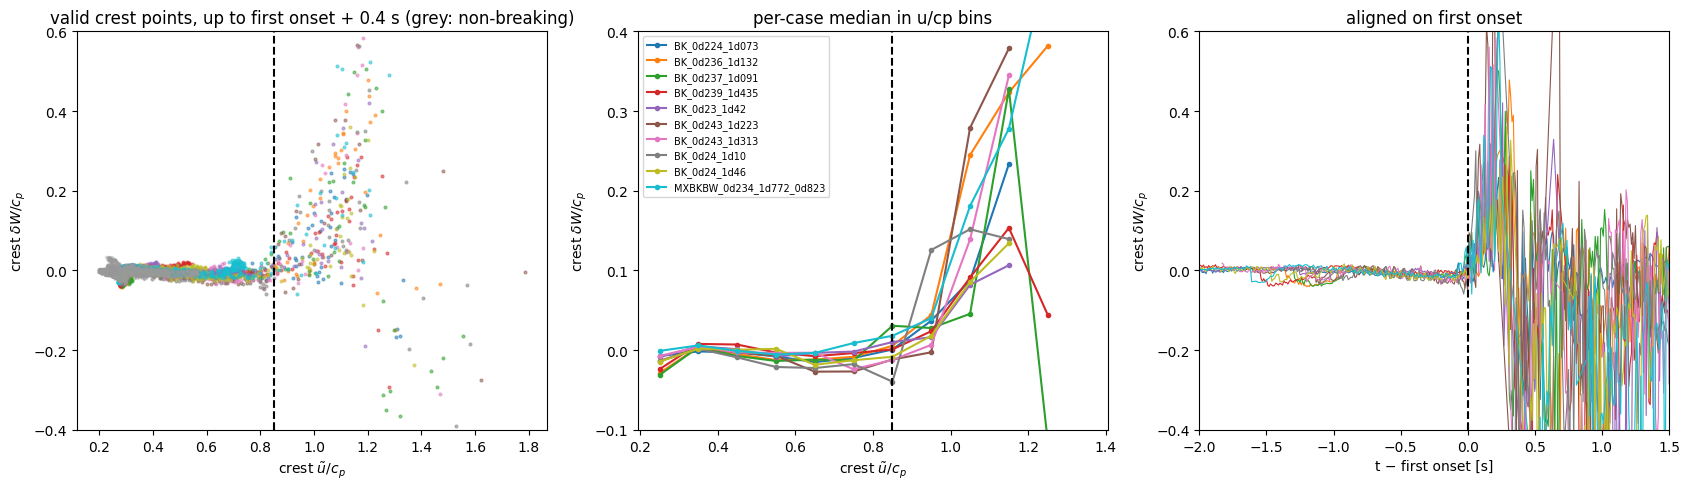

In [39]:
EXCLUDE = {"MXBKBW_0d222_1d337_1d248"}            # duplicate of 0d212
S = {}
for f in sorted((DATA / "for_claude" / "summaries").glob("summary_*.npz")):
    name = f.stem.replace("summary_test_", "")
    if name not in EXCLUDE:
        S[name] = dict(np.load(f, allow_pickle=True))

brk = [n for n, d in S.items() if len(d["onsets"]) and d["onsets"][0] > 1.5]
non = [n for n, d in S.items() if not len(d["onsets"])]
bins = np.arange(0.2, 1.45, 0.1); bc = 0.5 * (bins[1:] + bins[:-1])

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for j, n in enumerate(brk):
    d = S[n]; col = plt.cm.tab10(j % 10)
    t, ok, B, dWc = d["crest_t"], d["crest_ok"].astype(bool), d["crest_B"], d["crest_dW"]
    t1 = d["onsets"][0]
    first = ok & (t <= t1 + 0.4)                  # up to just after the first onset
    ax[0].scatter(B[first], dWc[first], s=4, color=col, alpha=0.5)
    med = [np.median(dWc[first & (B >= lo) & (B < hi)]) if (first & (B >= lo) & (B < hi)).sum() >= 3
           else np.nan for lo, hi in zip(bins[:-1], bins[1:])]
    ax[1].plot(bc, med, "o-", color=col, ms=3, label=n)
    ax[2].plot(t[ok] - t1, dWc[ok], color=col, lw=0.8)
for n in non:
    d = S[n]; ok = d["crest_ok"].astype(bool)
    ax[0].scatter(d["crest_B"][ok], d["crest_dW"][ok], s=2, color="0.6", alpha=0.3)

for a_ in ax[:2]:
    a_.axvline(0.85, ls="--", c="k"); a_.set_xlabel(r"crest $\tilde u/c_p$"); a_.set_ylabel(r"crest $\delta W/c_p$")
ax[0].set_ylim(-0.4, 0.6); ax[0].set_title("valid crest points, up to first onset + 0.4 s (grey: non-breaking)")
ax[1].set_ylim(-0.1, 0.4); ax[1].set_title("per-case median in u/cp bins"); ax[1].legend(fontsize=7)
ax[2].set_xlim(-2, 1.5); ax[2].set_ylim(-0.4, 0.6); ax[2].axvline(0, c="k", ls="--")
ax[2].set_xlabel("t − first onset [s]"); ax[2].set_ylabel(r"crest $\delta W/c_p$"); ax[2].set_title("aligned on first onset")
fig.tight_layout(); plt.show()

In [43]:
import json

SETTINGS = dict(
    KC_FACTOR=20,        # target resolution k_c = 20 k_p
    T_SKIP=1.5,          # start-up transient [s]
    TSTRIDE=2,           # every 2nd snapshot (0.02 s)
    XSTRIDE=4,           # every 4th grid point inside windows
    HALF_WIN=0.5,        # window half-width in peak wavelengths
    CREST_FRAC=0.3,      # crest = local max of filtered eta above 30% of the record max
    B_ON=0.85,           # onset threshold on max u/cp (for phase labels)
    ONSET_SPAN=0.3,      # 'onset' phase lasts this long after each crossing [s]
    SLOPE_MAX=1.3,       # validity: filtered slope below this
)
HELD_OUT = {"BK_0d239_1d435", "BK_0d243_1d223", "MXBKBW_0d234_1d772_0d823", "MXBK_0d189_1d252"}
EXCLUDE = {"MXBK_0d203_0d845", "MXBKBW_0d222_1d337_1d248"}      # failed run, duplicate
DS_DIR = DATA / "for_claude" / "dataset_v1"
DS_DIR.mkdir(parents=True, exist_ok=True)

FEATURES = [  # all non-dimensional with k_p, c_p, omega_p; all computable inside a potential-flow simulator
    "eta_k",      # k_p * eta
    "eta_x",      # slope
    "eta_xx_k",   # eta_xx / k_p
    "kappa_k",    # curvature / k_p
    "H_eta_k",    # k_p * spatial Hilbert transform of eta
    "env_k",      # k_p * envelope |eta + i H[eta]|
    "q_c",        # q / c_p  (tangential velocity = psi_x)
    "q_x_w",      # q_x / omega_p
    "Wpf_c",      # W_pf / c_p (potential-flow vertical velocity)
    "Wpf_x_w",    # (W_pf)_x / omega_p
    "upf_c",      # (q - W_pf * eta_x) / c_p : horizontal surface velocity potential flow implies
    "dx_crest_k", # k_p * (x - x_crest)  : position relative to the window's crest
    "Bcrest_pf",  # max upf/c_p inside this crest's window (simulator-available onset indicator)
]

def onset_times(Bmax, t, b_on):
    up = t[np.where((Bmax[1:] >= b_on) & (Bmax[:-1] < b_on))[0] + 1]
    return up[np.r_[True, np.diff(up) > 0.5]] if up.size else up

def sample_case(path, Tp=None, s=SETTINGS):
    c = load_case(path, Tp=Tp)
    eta, ux, uy, t, x = c["eta"], c["ux"], c["uy"], c["t"], c["x"]
    N, dx, L = c["N"], c["dx"], c["L"]
    k = wavenumbers(N, dx); kp, cp = c["kp"], c["cp"]; om = c["omega"]; KC = s["KC_FACTOR"] * kp
    lam = 2 * np.pi / kp
    # filtered fields for all snapshots (needed for the time derivative used in the quality check)
    ef, uf, wf = lowpass(eta, k, KC), lowpass(ux, k, KC), lowpass(uy, k, KC)
    eft = ddt4(ef, c["dt"])
    Bmax = ux.max(1) / cp
    onsets = onset_times(Bmax, t, s["B_ON"])
    half = int(round(s["HALF_WIN"] * lam / dx))
    rows = []; n_fail = 0; n_nocrest = 0
    idx_t = [i for i in range(2, len(t) - 2, s["TSTRIDE"]) if t[i] >= s["T_SKIP"]]
    emax = ef.max()
    for i in idx_t:
        e, u, w = ef[i], uf[i], wf[i]
        ex = ddx(e, k); exx = ddx(ex, k)
        # crests: local maxima of filtered eta above CREST_FRAC * record max
        pk = np.where((e > np.roll(e, 1)) & (e >= np.roll(e, -1)) & (e > s["CREST_FRAC"] * emax))[0]
        if pk.size == 0:
            n_nocrest += 1; continue
        q = u + w * ex
        psi, _ = integrate_x(q, k)
        try:
            Wp = conformal_vertical_velocity(e, psi, x, L)
        except ValueError:
            n_fail += 1; continue                             # overturned at this resolution: whole snapshot dropped
        dW = w - Wp
        upf = q - Wp * ex
        Heta = np.fft.irfft(-1j * np.sign(k) * np.fft.rfft(e), N)
        qx, Wpx = ddx(q, k), ddx(Wp, k)
        kappa = exx / (1 + ex**2) ** 1.5
        kin_res = eft[i] - (w - u * ex)                       # data-quality check (uses DNS ux, uy)
        # window points (union over crests; each point assigned to its nearest crest)
        sel = np.zeros(N, bool)
        for p in pk:
            sel[(np.arange(p - half, p + half + 1) % N)] = True
        pts = np.where(sel)[0][::s["XSTRIDE"]]
        dist = (pts[:, None] - pk[None, :] + N // 2) % N - N // 2   # periodic signed distance
        near = np.abs(dist).argmin(1)
        crest_of = pk[near]
        Bc = {p: (np.abs(upf[(np.arange(p - half, p + half + 1) % N)]).max() / cp) for p in pk}
        ph = 0
        if onsets.size and t[i] >= onsets[0]:
            ph = 1 if np.any((t[i] >= onsets) & (t[i] <= onsets + s["ONSET_SPAN"])) else 2
        rows.append(np.column_stack([
            kp * e[pts], ex[pts], exx[pts] / kp, kappa[pts] / kp, kp * Heta[pts],
            kp * np.hypot(e[pts], Heta[pts]), q[pts] / cp, qx[pts] / om, Wp[pts] / cp, Wpx[pts] / om,
            upf[pts] / cp, kp * dist[np.arange(len(pts)), near] * dx, [Bc[p] for p in crest_of],
            # --- target, quality, metadata ---
            dW[pts] / cp,                                     # target
            np.abs(kin_res[pts]) / cp,                        # kinematic residual (quality)
            (np.abs(ex[pts]) < s["SLOPE_MAX"]).astype(float), # valid flag
            ux[i, pts] / cp,                                  # DNS u/cp at the point (labels only, not a feature)
            np.full(len(pts), t[i]), x[pts], crest_of.astype(float), np.full(len(pts), ph),
        ]))
    data = np.vstack(rows).astype(np.float32)
    cols = FEATURES + ["dW_c", "kin_res_c", "valid", "uDNS_c", "t", "x", "crest_idx", "phase"]
    meta = dict(case=c["case"], Tp=c["Tp"], kp=kp, cp=cp, L=L, dx=dx, onsets=onsets.tolist(),
                n_snapshots=len(idx_t), n_map_failed=n_fail, n_no_crest=n_nocrest)
    return data, cols, meta

files = sorted(DATA.glob("*.mat"))
for p in files:
    name = p.stem.replace("test_", "").replace("_bak_surf1_pert", "")
    if name in EXCLUDE:
        continue
    out = DS_DIR / f"{name}.npz"
    if out.exists():
        print(f"skip (done): {name}"); continue
    t0 = time.time()
    try:
        data, cols, meta = sample_case(p)
        np.savez_compressed(out, data=data, cols=np.array(cols), held_out=name in HELD_OUT,
                            meta=json.dumps(meta), settings=json.dumps(SETTINGS))
        ph = data[:, cols.index("phase")]; v = data[:, cols.index("valid")] > 0
        print(f"{name}: {len(data):,} points ({v.mean():.2f} valid; {meta['n_map_failed']}/{meta['n_snapshots']} "
              f"snapshots dropped, map failed) | pre {np.mean(ph == 0):.2f}, "
              f"onset {np.mean(ph == 1):.2f}, post {np.mean(ph == 2):.2f} | "
              f"{'HELD-OUT' if name in HELD_OUT else 'train'} [{time.time() - t0:.0f}s]")
    except Exception as err:
        print(f"{name}: FAILED - {type(err).__name__}: {err}")
    gc.collect()

(DS_DIR / "manifest.json").write_text(json.dumps(dict(settings=SETTINGS, features=FEATURES,
    held_out=sorted(HELD_OUT), excluded=sorted(EXCLUDE)), indent=2))

BK_0d224_1d073: 32,351 points (1.00 valid; 0/425 snapshots dropped, map failed) | pre 0.41, onset 0.20, post 0.39 | train [81s]
BK_0d236_1d132: 40,430 points (1.00 valid; 0/425 snapshots dropped, map failed) | pre 0.18, onset 0.17, post 0.65 | train [70s]
BK_0d237_1d091: 37,782 points (1.00 valid; 0/425 snapshots dropped, map failed) | pre 0.17, onset 0.22, post 0.61 | train [79s]
BK_0d239_1d435: 68,853 points (1.00 valid; 0/425 snapshots dropped, map failed) | pre 0.26, onset 0.17, post 0.57 | HELD-OUT [76s]
BK_0d23_1d42: 54,511 points (1.00 valid; 0/390 snapshots dropped, map failed) | pre 0.62, onset 0.06, post 0.32 | train [71s]
BK_0d243_1d223: 47,115 points (1.00 valid; 2/425 snapshots dropped, map failed) | pre 0.18, onset 0.24, post 0.58 | HELD-OUT [79s]
BK_0d243_1d313: 56,257 points (1.00 valid; 0/425 snapshots dropped, map failed) | pre 0.21, onset 0.15, post 0.64 | train [79s]
BK_0d246_1d068: 30,153 points (1.00 valid; 7/400 snapshots dropped, map failed) | pre 0.00, onset 0.

606

### Regression Model fitting

In [44]:
import glob, json, time, warnings
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
warnings.filterwarnings("ignore")

DS_DIR = DATA / "for_claude" / "dataset_v1"
FEATS = json.loads((DS_DIR / "manifest.json").read_text())["features"]
GEO = ["eta_k", "eta_x", "eta_xx_k", "kappa_k", "H_eta_k", "env_k", "dx_crest_k"]   # from eta only
N_PER_CASE = 10_000          # random subsample per case (speed; neighbouring points are correlated anyway)
RUN_MLP = True              # MLP is ~6 min per scope; set True for the final ceiling
rng = np.random.default_rng(0)

D = {}
for f in sorted(DS_DIR.glob("*.npz")):
    z = np.load(f)
    D[f.stem] = (z["data"].astype(np.float64), bool(z["held_out"]))
    cols = list(z["cols"])
ix = {c: i for i, c in enumerate(cols)}
Y, PH = ix["dW_c"], ix["phase"]
train = [n for n, (d, h) in D.items() if not h]
sub = lambda d: d[rng.choice(len(d), min(N_PER_CASE, len(d)), replace=False)]
data = {n: sub(D[n][0][D[n][0][:, PH] <= 1]) for n in train}    # scope: pre-onset + onset

HGB = lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, l2_regularization=1.0, random_state=0)
MODELS = {
    "Ridge, all":           (lambda: make_pipeline(StandardScaler(), Ridge(1.0)), FEATS),
    "HistGB, all":          (HGB, FEATS),
    "HistGB, geometry":     (HGB, GEO),
    "HistGB, geometry+B":   (HGB, GEO + ["Bcrest_pf"]),
}
if RUN_MLP:
    MODELS["MLP 64x64, all"] = (lambda: make_pipeline(StandardScaler(), MLPRegressor(
        hidden_layer_sizes=(64, 64), alpha=1e-4, max_iter=200, early_stopping=True, random_state=0)), FEATS)

fe = [ix[c] for c in FEATS]
results = {m: [] for m in MODELS}; T_raw, T_cor, ON = [], [], []
for n in train:
    t0 = time.time(); trn = [m for m in train if m != n]
    # artefact model: δW in calm points (pre-onset) of the TRAINING folds only, where physics says δW = 0
    calm = np.vstack([data[m][data[m][:, PH] == 0] for m in trn])
    art = HGB().fit(calm[:, fe], calm[:, Y])
    tr, te = np.vstack([data[m] for m in trn]), data[n]
    ytr, yte = tr[:, Y] - art.predict(tr[:, fe]), te[:, Y] - art.predict(te[:, fe])   # corrected target
    for mname, (mk, fl) in MODELS.items():
        f2 = [ix[c] for c in fl]
        results[mname].append(mk().fit(tr[:, f2], ytr).predict(te[:, f2]))
    T_raw.append(te[:, Y]); T_cor.append(yte); ON.append(te[:, PH] == 1)
    print(f"fold {n}: done [{time.time() - t0:.0f}s]")

T_raw, T_cor, ON = map(np.concatenate, (T_raw, T_cor, ON))
print(f"\ncalm rms  raw {T_raw[~ON].std():.4f} -> corrected {T_cor[~ON].std():.4f} | "
      f"onset rms raw {T_raw[ON].std():.4f} -> corrected {T_cor[ON].std():.4f}")
for mname, preds in results.items():
    p = np.concatenate(preds)
    print(f"{mname:22s} pooled R2={r2_score(T_cor, p):.3f} | onset R2={r2_score(T_cor[ON], p[ON]):.3f} | "
          f"slope={np.polyfit(T_cor[ON], p[ON], 1)[0]:.2f}")

fold BK_0d224_1d073: done [95s]
fold BK_0d236_1d132: done [73s]
fold BK_0d237_1d091: done [73s]
fold BK_0d23_1d42: done [65s]
fold BK_0d243_1d313: done [56s]
fold BK_0d246_1d068: done [62s]
fold BK_0d24_1d10: done [82s]
fold BK_0d24_1d46: done [84s]
fold MXBK_0d174_1d050: done [60s]
fold MXBK_0d180_1d189: done [56s]
fold MXBKBW_0d183_1d918_0d826: done [55s]
fold MXBKBW_0d191_1d719_0d882: done [47s]
fold MXBKBW_0d205_1d836_0d818: done [69s]
fold MXBKBW_0d212_1d724_1d207: done [51s]

calm rms  raw 0.0127 -> corrected 0.0037 | onset rms raw 0.0772 -> corrected 0.0722
Ridge, all             pooled R2=0.739 | onset R2=0.813 | slope=0.74
HistGB, all            pooled R2=0.897 | onset R2=0.906 | slope=0.88
HistGB, geometry       pooled R2=0.388 | onset R2=0.420 | slope=0.39
HistGB, geometry+B     pooled R2=0.517 | onset R2=0.541 | slope=0.51
MLP 64x64, all         pooled R2=0.949 | onset R2=0.954 | slope=0.96


In [45]:
import json, warnings
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score
warnings.filterwarnings("ignore")

DS_DIR = DATA / "for_claude" / "dataset_v1"
OUT = DATA / "for_claude" / "pysr_v1"; OUT.mkdir(parents=True, exist_ok=True)
FEATS = json.loads((DS_DIR / "manifest.json").read_text())["features"]
VAL_CASES = {"BK_0d237_1d091", "BK_0d24_1d46", "MXBK_0d180_1d189"}   # model selection only (not the test set)
rng = np.random.default_rng(0)

D = {}
for f in sorted(DS_DIR.glob("*.npz")):
    z = np.load(f)
    if not bool(z["held_out"]):
        D[f.stem] = z["data"].astype(np.float64)
    cols = list(z["cols"])
ix = {c: i for i, c in enumerate(cols)}; Y, PH = ix["dW_c"], ix["phase"]; fe = [ix[c] for c in FEATS]
fit_cases = [n for n in D if n not in VAL_CASES]
HGB = lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, l2_regularization=1.0, random_state=0)

# 1) artefact model from calm (pre-onset) points of the FIT cases; corrected target for everything
calm = np.vstack([d[d[:, PH] == 0][rng.choice((d[:, PH] == 0).sum(), min(10_000, (d[:, PH] == 0).sum()), replace=False)]
                  for n, d in D.items() if n in fit_cases])
art = HGB().fit(calm[:, fe], calm[:, Y])
scoped = {n: d[d[:, PH] <= 1] for n, d in D.items()}                     # pre-onset + onset
ystar = {n: d[:, Y] - art.predict(d[:, fe]) for n, d in scoped.items()}

# 2) teacher on fit cases, scored on validation cases; permutation importance there
def sample(n, k=10_000):
    i = rng.choice(len(scoped[n]), min(k, len(scoped[n])), replace=False); return scoped[n][i], ystar[n][i]
Xf, yf = map(np.concatenate, zip(*[sample(n) for n in fit_cases]))
Xv, yv = map(np.concatenate, zip(*[sample(n) for n in VAL_CASES]))
teacher = HGB().fit(Xf[:, fe], yf)
on_v = Xv[:, PH] == 1
print(f"teacher on validation cases: R2={r2_score(yv, teacher.predict(Xv[:, fe])):.3f}, "
      f"onset R2={r2_score(yv[on_v], teacher.predict(Xv[on_v][:, fe])):.3f}")
imp = permutation_importance(teacher, Xv[:, fe], yv, n_repeats=5, random_state=0, scoring="r2")
order = np.argsort(-imp.importances_mean)
print("permutation importance (drop in validation R2 when a feature is shuffled):")
for j in order:
    print(f"  {FEATS[j]:11s} {imp.importances_mean[j]:+.3f} ± {imp.importances_std[j]:.3f}")

# 3) PySR sample: case-balanced, onset-enriched, from FIT cases; validation sample from VAL cases
def pysr_sample(cases, n_onset=300, n_pre=150):
    rows, ys, grp = [], [], []
    for n in cases:
        d, y = scoped[n], ystar[n]
        for ph, k in ((1, n_onset), (0, n_pre)):
            idx = np.where(d[:, PH] == ph)[0]
            if idx.size:
                pick = rng.choice(idx, min(k, idx.size), replace=False)
                rows.append(d[pick]); ys.append(y[pick]); grp += [n] * len(pick)
    return np.vstack(rows), np.concatenate(ys), np.array(grp)
Xp, yp, gp = pysr_sample(fit_cases); Xq, yq, gq = pysr_sample(sorted(VAL_CASES))
for name, X_, y_, g_ in (("train", Xp, yp, gp), ("val", Xq, yq, gq)):
    np.savez(OUT / f"pysr_{name}.npz", X=X_[:, fe].astype(np.float32), y=y_.astype(np.float32),
             y_raw=X_[:, Y].astype(np.float32), phase=X_[:, PH].astype(np.int8), case=g_, features=np.array(FEATS))
    print(f"pysr_{name}: {len(y_)} points from {len(set(g_))} cases (onset fraction {np.mean(X_[:, PH] == 1):.2f})")
(OUT / "pysr_manifest.json").write_text(json.dumps(dict(features=FEATS, fit_cases=fit_cases,
    val_cases=sorted(VAL_CASES), target="dW_c minus calm-artefact model (HistGB on pre-onset of fit cases)"), indent=2))

teacher on validation cases: R2=0.936, onset R2=0.942
permutation importance (drop in validation R2 when a feature is shuffled):
  Wpf_c       +12.493 ± 0.057
  H_eta_k     +7.438 ± 0.058
  eta_x       +0.190 ± 0.003
  q_x_w       +0.166 ± 0.002
  Bcrest_pf   +0.134 ± 0.001
  q_c         +0.039 ± 0.002
  upf_c       +0.036 ± 0.001
  env_k       +0.035 ± 0.001
  dx_crest_k  +0.029 ± 0.001
  eta_k       +0.021 ± 0.001
  kappa_k     +0.012 ± 0.000
  eta_xx_k    +0.005 ± 0.000
  Wpf_x_w     +0.002 ± 0.000
pysr_train: 3300 points from 11 cases (onset fraction 0.55)
pysr_val: 1050 points from 3 cases (onset fraction 0.57)


676

#### PySR Run 1 - target = "y"

In [ ]:
import json
from pysr import PySRRegressor
from sklearn.metrics import r2_score

P_DIR = DATA / "for_claude" / "pysr_v1"
tr, va = np.load(P_DIR / "pysr_train.npz", allow_pickle=True), np.load(P_DIR / "pysr_val.npz", allow_pickle=True)
FEATS = list(tr["features"])
TARGET = "y"            
SEED = 0

model = PySRRegressor(
    binary_operators=["+", "-", "*", "/"],
    unary_operators=["square", "cube", "abs", "tanh"],
    nested_constraints={"tanh": {"tanh": 0}, "square": {"square": 1, "cube": 0}, "cube": {"square": 0, "cube": 0}},
    constraints={"/": (-1, 9)},
    maxsize=20,
    parsimony=1e-4,
    niterations=200,
    populations=30,
    population_size=50,
    random_state=SEED,
    parallelism="multithreading",
    output_directory=str(P_DIR / "runs"),
    progress=False,
)
model.fit(tr["X"], tr[TARGET], variable_names=FEATS)

on = va["phase"] == 1
rows = []
for i, eq in model.equations_.iterrows():
    p = model.predict(va["X"], index=i)
    rows.append((eq["complexity"], eq["loss"], r2_score(va[TARGET], p), r2_score(va[TARGET][on], p[on]), eq["equation"]))
print(f"{'cx':>3} {'train loss':>10} {'val R2':>7} {'val onset R2':>12}  equation")
for cx, loss, r2, r2o, e in rows:
    print(f"{cx:3d} {loss:10.2e} {r2:7.3f} {r2o:12.3f}  {e}")

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


Compiling Julia backend...
[ Info: Started!



Expressions evaluated per second: 7.870e+04
Progress: 251 / 6000 total iterations (4.183%)
════════════════════════════════════════════════════════════════════════════════════════════════════
───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           2.897e-03  0.000e+00  y = 0.0024259
3           9.926e-04  5.355e-01  y = H_eta_k - Wpf_c
4           9.689e-04  2.425e-02  y = tanh(H_eta_k) - Wpf_c
5           6.958e-04  3.310e-01  y = (H_eta_k - Wpf_c) / 1.3667
7           6.041e-04  7.065e-02  y = (H_eta_k - (Wpf_c / 0.91757)) / 1.5039
9           5.997e-04  3.652e-03  y = (((H_eta_k * 0.92235) - Wpf_c) / 1.4372) - 0.0029972
10          5.560e-04  7.582e-02  y = ((H_eta_k * 0.94612) - Wpf_c) / (1.6388 - abs(Wpf_c))
───────────────────────────────────────────────────────────────────────────────────────────────────
═════════════════════════════════════════════════════════════════════════════

[ Info: Final population:
[ Info: Results saved to:


 cx train loss  val R2 val onset R2  equation
  1   2.90e-03  -0.001       -0.005  0.0024318756
  3   9.93e-04   0.635        0.737  H_eta_k - Wpf_c
  4   9.69e-04   0.647        0.751  tanh(H_eta_k) - Wpf_c
  5   6.96e-04   0.724        0.777  (H_eta_k - Wpf_c) / 1.3667455
  6   6.71e-04   0.737        0.792  (tanh(H_eta_k) - Wpf_c) * 0.7324222
  7   6.04e-04   0.771        0.828  (H_eta_k - (Wpf_c / 0.9175672)) / 1.5038724
  8   5.75e-04   0.770        0.808  (H_eta_k - Wpf_c) * (abs(Wpf_c) + 0.4888071)
  9   5.48e-04   0.801        0.839  ((H_eta_k - Wpf_c) - (dx_crest_k * 0.009133914)) * 0.7411361
 10   5.44e-04   0.806        0.848  ((H_eta_k - Wpf_c) * 0.7320895) - (tanh(dx_crest_k) * 0.01492673)
 11   5.30e-04   0.812        0.849  ((H_eta_k - Wpf_c) - ((dx_crest_k * 0.015974708) * Bcrest_pf)) * 0.7232301
 12   4.65e-04   0.835        0.857  tanh(Bcrest_pf + 0.30714014) * ((H_eta_k - Wpf_c) - (dx_crest_k * 0.010122366))
 13   4.65e-04   0.839        0.865  ((H_eta_k - Wpf_c) - (

#### PySR Run 1 - target = "y_raw"

In [47]:
import json
from pysr import PySRRegressor
from sklearn.metrics import r2_score

P_DIR = DATA / "for_claude" / "pysr_v1"
tr, va = np.load(P_DIR / "pysr_train.npz", allow_pickle=True), np.load(P_DIR / "pysr_val.npz", allow_pickle=True)
FEATS = list(tr["features"])
TARGET = "y_raw"
SEED = 0

model = PySRRegressor(
    binary_operators=["+", "-", "*", "/"],
    unary_operators=["square", "cube", "abs", "tanh"],
    nested_constraints={"tanh": {"tanh": 0}, "square": {"square": 1, "cube": 0}, "cube": {"square": 0, "cube": 0}},
    constraints={"/": (-1, 9)},
    maxsize=20,
    parsimony=1e-4,
    niterations=200,
    populations=30,
    population_size=50,
    random_state=SEED,
    parallelism="multithreading",
    output_directory=str(P_DIR / "runs"),
    progress=False,
)
model.fit(tr["X"], tr[TARGET], variable_names=FEATS)

on = va["phase"] == 1
rows = []
for i, eq in model.equations_.iterrows():
    p = model.predict(va["X"], index=i)
    rows.append((eq["complexity"], eq["loss"], r2_score(va[TARGET], p), r2_score(va[TARGET][on], p[on]), eq["equation"]))
print(f"{'cx':>3} {'train loss':>10} {'val R2':>7} {'val onset R2':>12}  equation")
for cx, loss, r2, r2o, e in rows:
    print(f"{cx:3d} {loss:10.2e} {r2:7.3f} {r2o:12.3f}  {e}")

[ Info: Started!



Expressions evaluated per second: 1.010e+05
Progress: 341 / 6000 total iterations (5.683%)
════════════════════════════════════════════════════════════════════════════════════════════════════
───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           3.430e-03  0.000e+00  y = 0.0049785
3           6.835e-04  8.065e-01  y = H_eta_k - Wpf_c
4           6.673e-04  2.397e-02  y = H_eta_k - tanh(Wpf_c)
5           5.728e-04  1.527e-01  y = (Wpf_c - H_eta_k) * -0.83615
7           5.562e-04  1.471e-02  y = ((Wpf_c * -1.0315) + H_eta_k) * 0.80776
9           4.815e-04  7.217e-02  y = ((Wpf_c - H_eta_k) / -1.1854) - (dx_crest_k * 0.005323...
                                      8)
───────────────────────────────────────────────────────────────────────────────────────────────────
════════════════════════════════════════════════════════════════════════════════════════════════════
Press 'q' and then 

[ Info: Final population:
[ Info: Results saved to:


 cx train loss  val R2 val onset R2  equation
  1   3.43e-03  -0.000       -0.007  0.0049983915
  3   6.83e-04   0.777        0.833  H_eta_k - Wpf_c
  4   6.67e-04   0.777        0.827  H_eta_k - tanh(Wpf_c)
  5   5.73e-04   0.806        0.845  (Wpf_c - H_eta_k) * -0.83614874
  7   5.56e-04   0.813        0.854  (Wpf_c - H_eta_k) / (-0.95708865 - env_k)
  8   5.51e-04   0.819        0.860  (Wpf_c - H_eta_k) / (-1.0342923 - abs(eta_k))
  9   4.81e-04   0.849        0.887  ((Wpf_c - H_eta_k) / -1.1854951) - (dx_crest_k * 0.005323729)
 11   4.51e-04   0.856        0.896  ((Wpf_c - H_eta_k) / -1.1711451) - ((dx_crest_k - eta_xx_k) * 0.0056405272)
 12   4.34e-04   0.868        0.885  ((Wpf_c - H_eta_k) / -1.3570818) - ((Wpf_c + tanh(eta_x)) * 0.16473109)
 13   4.33e-04   0.863        0.901  ((Wpf_c - H_eta_k) / -1.1487736) - ((dx_crest_k - (eta_xx_k - q_x_w)) * 0.006159293)
 15   4.05e-04   0.871        0.899  ((Wpf_c - H_eta_k) / -1.1332799) - ((dx_crest_k - (eta_xx_k - (eta_x / 0.18537822